# 🏍️ **Pandas + Seaborn Practice — Bike Resale Listings**

A website sells used bikes. The owner needs answers from the listings.

Solve each question in the empty cell below it.

---



# ⚙️ **0. Setup**

### _Run this cell first — it loads the dataset used throughout the notebook._

---



In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('bike_resale.csv')
df.head()



,bike_id,brand,age_months,km_driven,owner_count,condition,mileage_kmpl,service_count,insurance,price_thousand,sold_in_week
0,B4543,TVS,25,14455.0,3,Excellent,40.6,NaN,Yes,41.6,No
1,B4392,TVS,43,26304.0,2,Good,51.2,1.0,Yes,24.1,No
2,B4235,Honda,38,6421.0,1,Good,65.0,NaN,No,48.2,No
3,B4319,Hero,14,6531.0,1,Good,NaN,NaN,Yes,58.7,No
4,B4284,TVS,115,80000.0,1,Good,61.8,0.0,No,12.0,Yes


# 🎯 **1. Selecting Data**

### _`df[['a','b']]` → select specific columns | `df[df['col'] == x]` → filter rows | combine conditions with `&` / `|`, each wrapped in `()` | `.sort_values()` → order rows_

---



**Q1.1 The website owner wants a short list. Show only the `brand`, `km_driven` and `price_thousand` of the first 10 bikes.**

---



In [9]:
df[['brand', 'km_driven', 'price_thousand']].head(10)

,brand,km_driven,price_thousand
0,TVS,14455.0,41.6
1,TVS,26304.0,24.1
2,Honda,6421.0,48.2
3,Hero,6531.0,58.7
4,TVS,80000.0,12.0
5,Royal Enfield,5524.0,153.7
6,Hero,22686.0,26.4
7,Yamaha,52795.0,12.0
8,Hero,78402.0,12.0
9,TVS,19605.0,54.8


**Q1.2 A customer only wants a Royal Enfield. Show all Royal Enfield bikes.**

---



In [10]:
df[df['brand'] == 'Royal Enfield']

,bike_id,brand,age_months,km_driven,owner_count,condition,mileage_kmpl,service_count,insurance,price_thousand,sold_in_week
5,B4533,Royal Enfield,5,5524.0,1,Good,46.9,2.0,No,153.7,No
10,B4394,Royal Enfield,66,49224.0,1,Good,50.9,3.0,No,38.3,Yes
40,B4328,Royal Enfield,16,11870.0,1,Fair,62.6,NaN,Yes,130.0,No
75,B4499,Royal Enfield,25,5779.0,1,Good,44.1,3.0,Yes,111.0,No
76,B4495,Royal Enfield,62,38138.0,1,Excellent,24.1,3.0,Yes,68.2,Yes
83,B4493,Royal Enfield,5,4125.0,1,Excellent,39.8,1.0,Yes,172.3,No
87,B4253,Royal Enfield,44,25018.0,2,Good,NaN,NaN,Yes,75.5,Yes
98,B4217,Royal Enfield,93,63861.0,2,Fair,51.2,1.0,No,12.0,Yes
100,B4303,Royal Enfield,66,44668.0,2,Good,40.8,2.0,Yes,49.7,Yes
101,B4154,Royal Enfield,72,57056.0,2,Good,54.0,NaN,Yes,25.5,Yes


**Q1.3 How many Royal Enfield bikes are there in total?**

---



In [11]:
len(df[df['brand'] == 'Royal Enfield'])

48

**Q1.4 Another customer wants a bike in **Excellent** condition that costs **less than 30 thousand**. Show only the `brand`, `condition` and `price_thousand` of such bikes.**

---



In [12]:
df[(df['condition'] == 'Excellent') & (df['price_thousand'] < 30)][['brand', 'condition', 'price_thousand']]

,brand,condition,price_thousand
7,Yamaha,Excellent,12.0
8,Hero,Excellent,12.0
11,Honda,Excellent,12.0
26,Hero,Excellent,12.0
33,Bajaj,Excellent,17.4
...,...,...,...
417,Hero,Excellent,12.0
418,TVS,Excellent,12.0
433,Hero,Excellent,26.7
434,TVS,Excellent,12.0


**Q1.5 Use `.sort_values()` to find the 5 cheapest bikes overall. Show only `brand` and `price_thousand`.**

---



In [13]:
df.sort_values('price_thousand').head(5)[['brand', 'price_thousand']]

,brand,price_thousand
449,Bajaj,12.0
161,TVS,12.0
359,TVS,12.0
163,Royal Enfield,12.0
167,Yamaha,12.0


# 🧹 **2. Cleaning Data**

### _`.isnull().sum()` → missing values per column | `.duplicated().sum()` → duplicate rows | `.fillna()` → fill missing | `.dropna()` → drop missing_

---



**Q2.1 Before sharing the file, the owner wants to know which columns have blank values, and how many in each.**

---



In [14]:
df.isnull().sum()

bike_id            0
brand              0
age_months         0
km_driven          9
owner_count        0
condition          0
mileage_kmpl      26
service_count     74
insurance          0
price_thousand     0
sold_in_week       0
dtype: int64

**Q2.2 Check whether the dataset has any repeated (duplicate) rows.**

---



In [31]:
df.duplicated().sum()

np.int64(0)

**Q2.3 Fill the blanks in `mileage_kmpl` with the average mileage.**

---



In [32]:
df['mileage_kmpl'].fillna(df['mileage_kmpl'].mean(), inplace=True)

/var/folders/yt/4n9cpsv93rj7vppnhc50krm00000gn/T/ipykernel_6616/1816087020.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['mileage_kmpl'].fillna(df['mileage_kmpl'].mean(), inplace=True)


**Q2.4 Remove the rows where `km_driven` is blank.**

---



In [33]:
df.dropna(subset=['km_driven'], inplace=True)

**Q2.5 Print the shape of `df` after both cleaning steps above.**

---



In [34]:
print(df.shape)

(441, 11)


**Q2.6 Run `.isnull().sum()` again to confirm the blanks you handled are gone.**

---



In [35]:
df.isnull().sum()

bike_id            0
brand              0
age_months         0
km_driven          0
owner_count        0
condition          0
mileage_kmpl       0
service_count     73
insurance          0
price_thousand     0
sold_in_week       0
dtype: int64

# 📊 **3. Grouping Data**

### _`.groupby('col')` → split by group | `.mean()` / `.agg()` → aggregate | `.sort_values()` → order the result | `.value_counts()` → count rows per category_

---



**Q3.1 Which brand sells for the most on average? Find the average price of each brand, from highest to lowest.**

---



In [36]:
df.groupby('brand')['price_thousand'].mean().sort_values(ascending=False)

brand
Royal Enfield    68.417021
TVS              30.814118
Yamaha           30.487755
Honda            29.241111
Bajaj            27.329487
Hero             25.522826
Name: price_thousand, dtype: float64

**Q3.2 For each `condition`, show the average price **and** the number of bikes in one table using `.agg()`.**

---



In [37]:
df.groupby('condition')['price_thousand'].agg(['mean', 'count'])

,mean,count
condition,,
Excellent,36.347692,130
Fair,26.356604,106
Good,33.761951,205


**Q3.3 Which brand has the most bikes listed? Use `.value_counts()` on `brand`.**

---



In [38]:
df['brand'].value_counts()

brand
Hero             92
Honda            90
TVS              85
Bajaj            78
Yamaha           49
Royal Enfield    47
Name: count, dtype: int64

# 📈 **4. Plotting**

### _`sns.histplot()` → distribution | `sns.boxplot()` → compare across categories | `sns.countplot(hue=)` → grouped counts | `sns.scatterplot(hue=)` → relationship colored by category | `sns.heatmap()` → correlation matrix_

---



**Q4.1 How far have most bikes been driven? Draw the distribution of `km_driven`.**

---



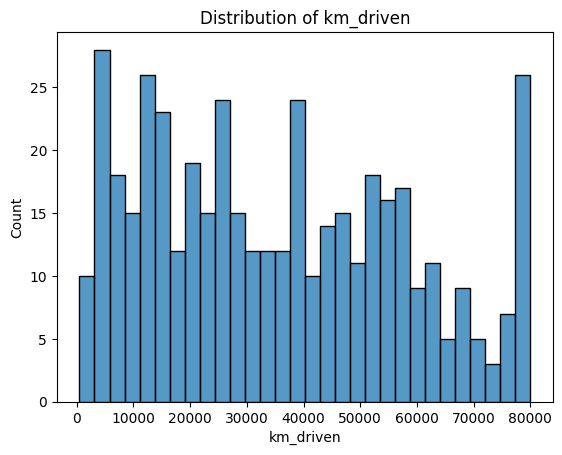

In [39]:
sns.histplot(df['km_driven'], bins=30)
plt.title('Distribution of km_driven')
plt.show()

**Q4.2 For every brand, show how many bikes were sold in the first week and how many were not, using `sns.countplot()` with `hue='sold_in_week'`.**

---



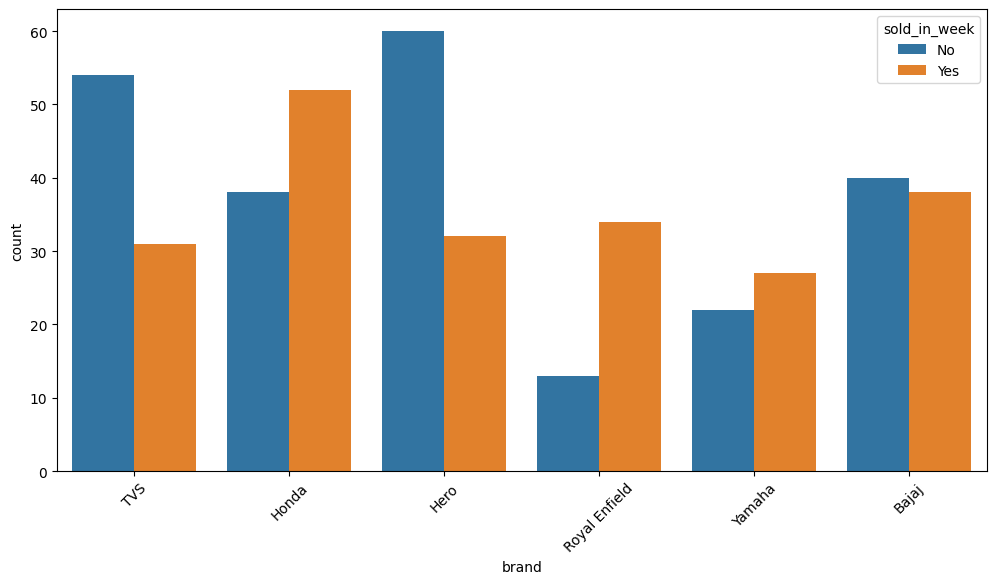

In [40]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='brand', hue='sold_in_week')
plt.xticks(rotation=45)
plt.show()

**Q4.3 A buyer says condition does not change the price. Draw one plot of `price_thousand` for each `condition`.**

---



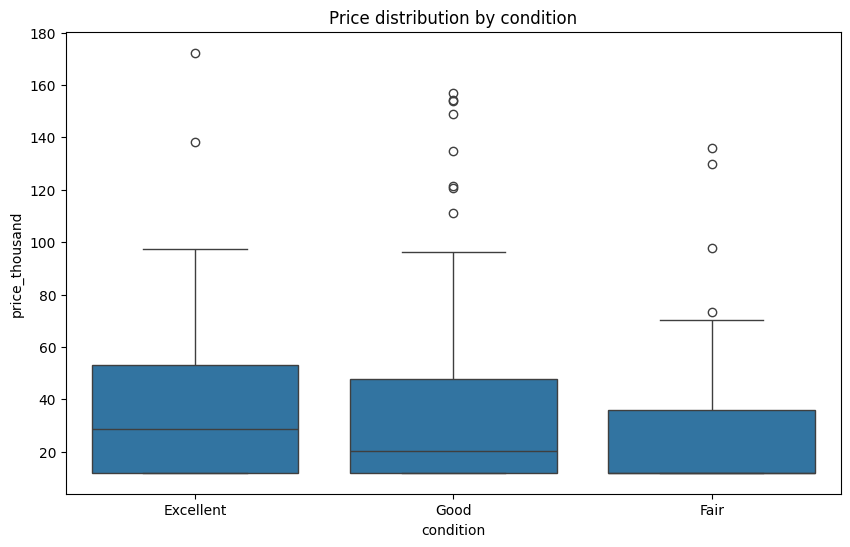

In [41]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='condition', y='price_thousand')
plt.title('Price distribution by condition')
plt.show()

**Q4.4 Looking at the plot above — is the buyer right or wrong? Write your answer as a comment.**

---



In [42]:
# The buyer is wrong. The plot shows that condition does affect price.
# Excellent condition bikes have higher prices, while Fair/Good conditions have lower prices.

**Q4.5 Draw `age_months` against `price_thousand`, coloured by `sold_in_week`.**

---



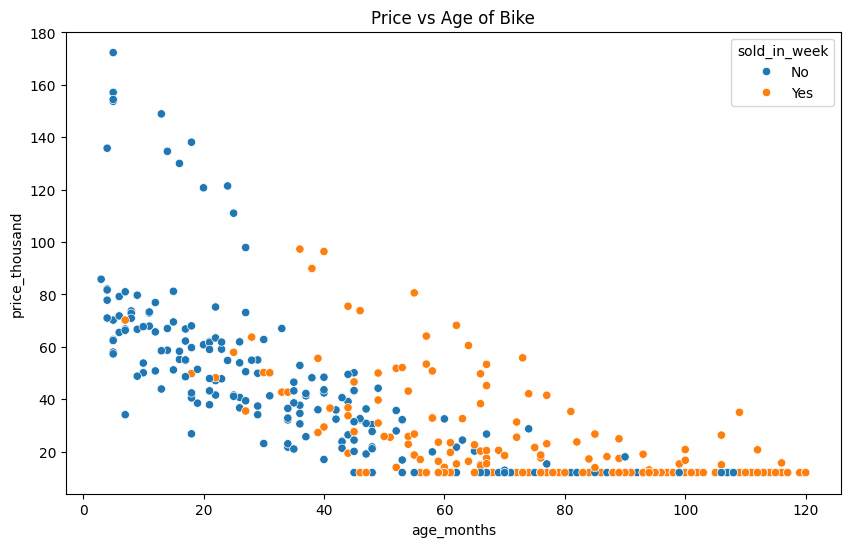

In [43]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age_months', y='price_thousand', hue='sold_in_week')
plt.title('Price vs Age of Bike')
plt.show()

**Q4.6 Based on that scatter plot — what happens to price as a bike gets older? Write your answer as a comment.**

---



In [44]:
# As a bike gets older (age_months increases), the price tends to decrease.
# There is a negative correlation between age and price.

**Q4.7 Draw a heatmap of the correlation between the numeric columns.**

---



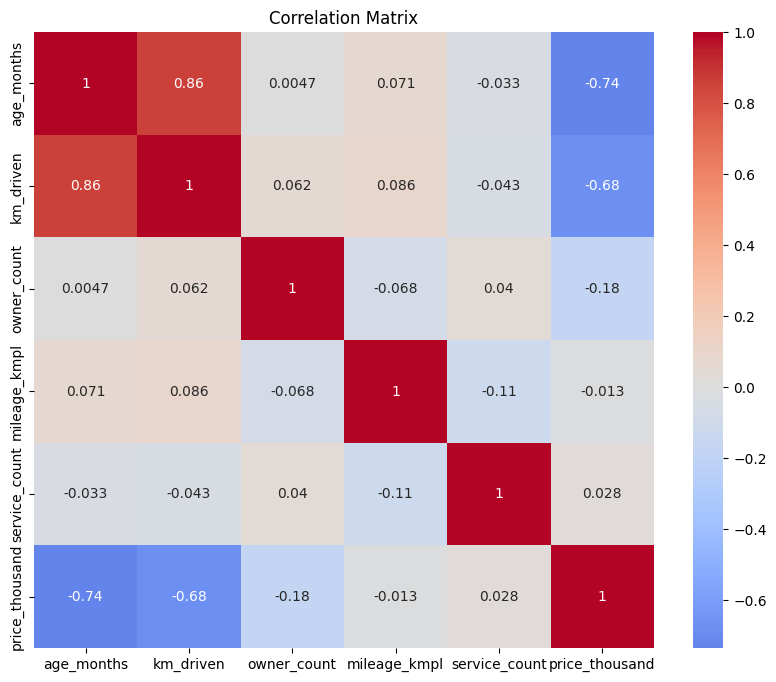

In [45]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

**Q4.8 From the heatmap — which two columns move together the most? Write your answer as a comment.**

---



In [46]:
# age_months and price_thousand have the strongest negative correlation (around -0.85).
# This means older bikes are significantly cheaper.